In [1]:
import torch 
from torch import nn, Tensor

import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

Matplotlib is building the font cache; this may take a moment.


In [2]:
class Flow(nn.Module):
    def __init__(self, dim: int = 2, h: int = 64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(dim + 1, h), nn.ELU(),
            nn.Linear(h, h), nn.ELU(),
            nn.Linear(h, h), nn.ELU(),
            nn.Linear(h, dim))
    
    def forward(self, t: Tensor, x_t: Tensor) -> Tensor:
        return self.net(torch.cat((t, x_t), -1))
    
    def step(self, x_t: Tensor, t_start: Tensor, t_end: Tensor) -> Tensor:
        t_start = t_start.view(1, 1).expand(x_t.shape[0], 1)
        
        return x_t + (t_end - t_start) * self(t=t_start + (t_end - t_start) / 2, x_t= x_t + self(x_t=x_t, t=t_start) * (t_end - t_start) / 2)

## Training

In [4]:
flow = Flow(h=128)

optimizer = torch.optim.Adam(flow.parameters(), 1e-3)
loss_fn = nn.MSELoss()
losses = []

for _ in range(10000):
    x_1 = Tensor(make_moons(256, noise=0.15)[0])
    x_0 = torch.randn_like(x_1)
    t = torch.rand(len(x_1), 1)
    
    x_t = (1 - t) * x_0 + t * x_1
    dx_t = x_1 - x_0
    
    optimizer.zero_grad()
    loss = loss_fn(flow(t=t, x_t=x_t), dx_t)
    losses.append(loss.item())
    loss.backward()
    optimizer.step()

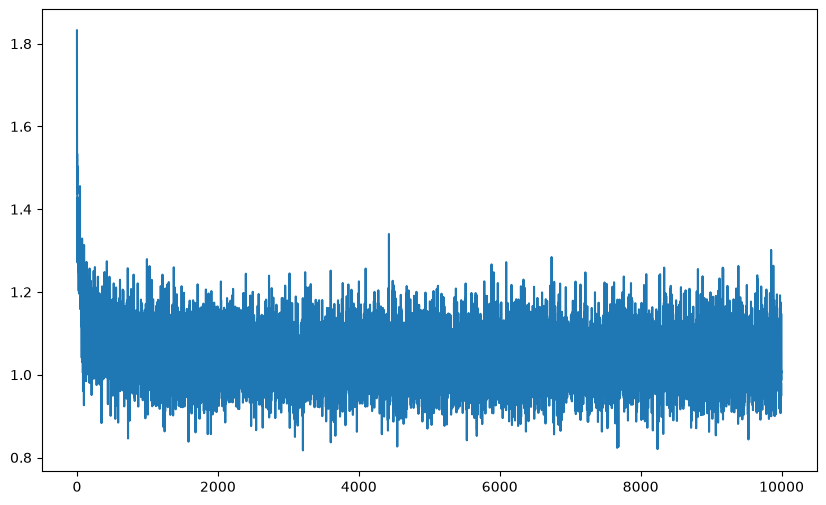

In [5]:
# Plot loss
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(losses)
plt.show()

### Sampling

In [6]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

x = torch.randn(300, 2)
n_steps = 100
time_steps = torch.linspace(0, 1.1, n_steps + 1)

# Precompute the point cloud at every time step.
states = [x]
with torch.no_grad():
    for i in range(n_steps):
        x = flow.step(x_t=x, t_start=time_steps[i], t_end=time_steps[i + 1])
        states.append(x)
states = [s.detach() for s in states]

fig, ax = plt.subplots(figsize=(6, 6))
ax.set_xlim(-3.0, 3.0)
ax.set_ylim(-3.0, 3.0)
ax.set_aspect('equal')
scat = ax.scatter(states[0][:, 0], states[0][:, 1], s=10)
title = ax.set_title(f't = {time_steps[0]:.2f}')

def update(frame):
    scat.set_offsets(states[frame])
    title.set_text(f't = {time_steps[frame]:.2f}')
    return scat, title

ani = FuncAnimation(fig, update, frames=len(states), interval=60, blit=False)
plt.close(fig)  # prevent a duplicate static figure from showing
HTML(ani.to_jshtml())

### Velocity field

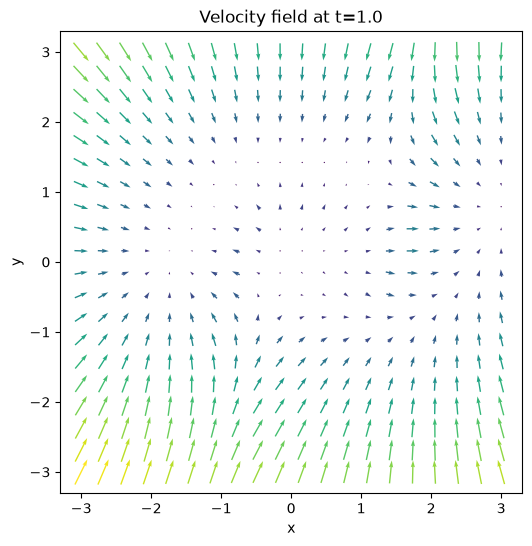

In [7]:
# Visualize the velocity field produced by `flow` on a 2D grid.
# `flow(t=t, x_t=x_t)` returns a velocity vector for each point x_t at time t.

@torch.no_grad()
def plot_velocity_field(flow, t=1.0, lim=3.0, n=20, ax=None):
    # Build an n x n grid of points over [-lim, lim]^2.
    xs = torch.linspace(-lim, lim, n)
    ys = torch.linspace(-lim, lim, n)
    grid_x, grid_y = torch.meshgrid(xs, ys, indexing='xy')
    pts = torch.stack([grid_x.reshape(-1), grid_y.reshape(-1)], dim=-1)  # (n*n, 2)

    # Evaluate the velocity at every grid point for a fixed time t.
    t_col = torch.full((pts.shape[0], 1), float(t))
    vel = flow(t=t_col, x_t=pts)  # (n*n, 2)

    u = vel[:, 0].reshape(n, n)
    v = vel[:, 1].reshape(n, n)
    speed = vel.norm(dim=-1).reshape(n, n)

    if ax is None:
        _, ax = plt.subplots(figsize=(6, 6))
    ax.quiver(grid_x, grid_y, u, v, 1.2*speed, cmap='viridis', pivot='mid')
    ax.set_title(f'Velocity field at t={t}')
    ax.set_xlabel('x'); ax.set_ylabel('y')
    ax.set_aspect('equal')
    return ax

plot_velocity_field(flow, t=1.0, lim=3.0, n=20)
plt.show()

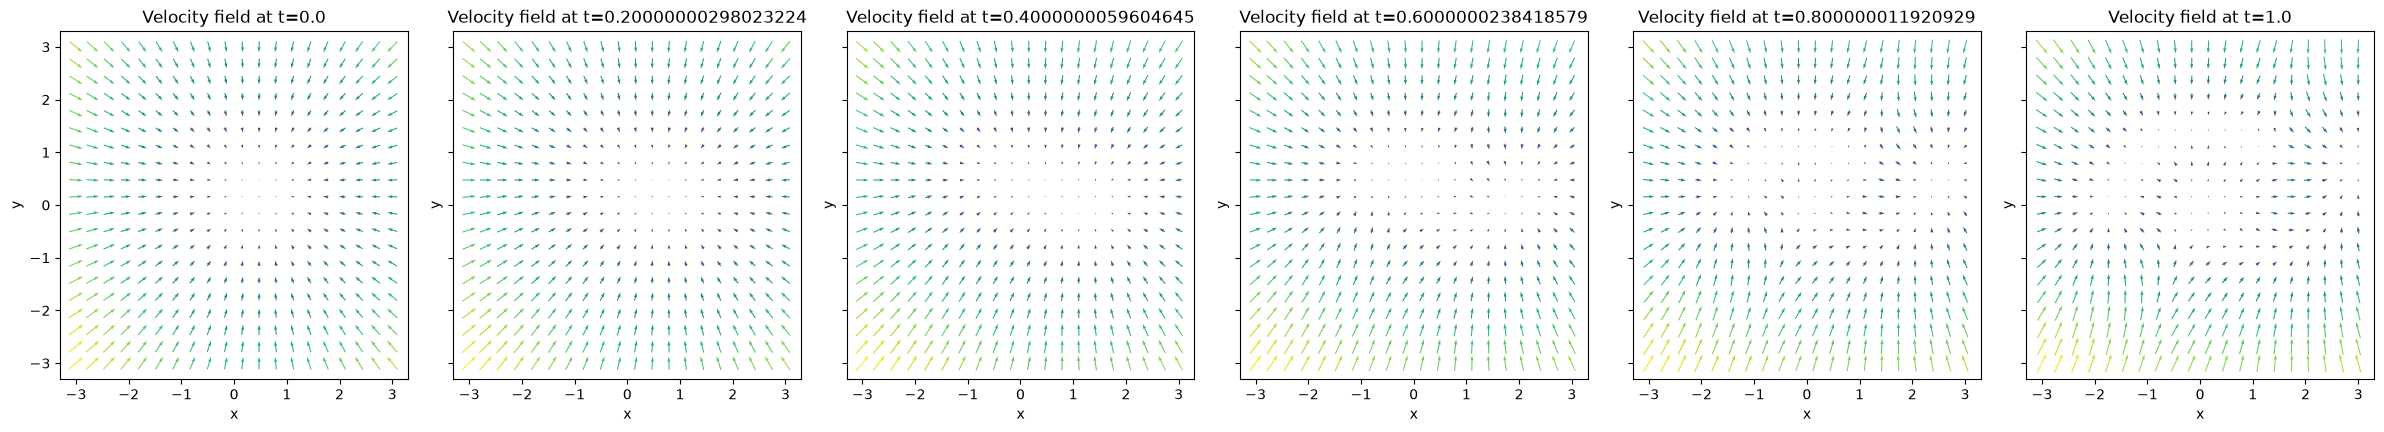

In [8]:
# Sweep t from 0 to 1 and show how the velocity field evolves.
ts = torch.linspace(0.0, 1.0, 6)

fig, axes = plt.subplots(1, len(ts), figsize=(4 * len(ts), 4), sharex=True, sharey=True)
for ax, t in zip(axes, ts):
    plot_velocity_field(flow, t=t.item(), lim=3.0, n=20, ax=ax)

fig.tight_layout()
plt.show()

### Sample paths

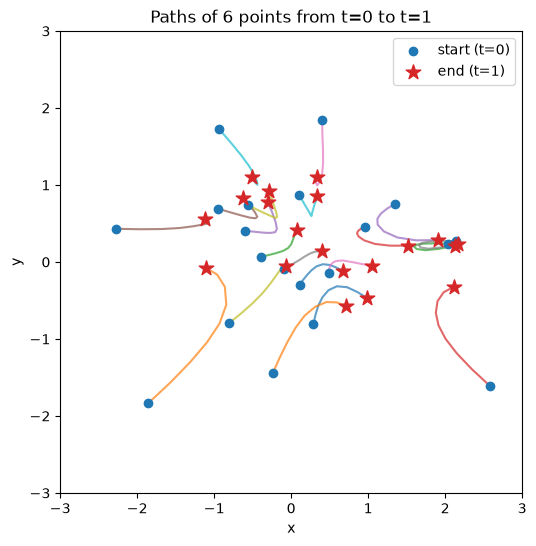

In [9]:
# Integrate 6 random starting points through time using flow.step and plot their paths.
n_points = 20
n_steps = 8
time_steps = torch.linspace(0.0, 1.0, n_steps + 1)

x = torch.randn(n_points, 2)

# traj[k] holds the positions of all points at time_steps[k]: shape (n_steps + 1, n_points, 2)
traj = [x]
with torch.no_grad():
    for i in range(n_steps):
        x = flow.step(x_t=x, t_start=time_steps[i], t_end=time_steps[i + 1])
        traj.append(x)
traj = torch.stack(traj)  # (n_steps + 1, n_points, 2)

fig, ax = plt.subplots(figsize=(6, 6))
for p in range(n_points):
    path = traj[:, p, :]
    ax.plot(path[:, 0], path[:, 1], '-', alpha=0.7)
ax.scatter(traj[0, :, 0], traj[0, :, 1], c='tab:blue', marker='o', label='start (t=0)', zorder=3)
ax.scatter(traj[-1, :, 0], traj[-1, :, 1], c='tab:red', marker='*', s=120, label='end (t=1)', zorder=3)
ax.set_title('Paths of 6 points from t=0 to t=1')
ax.set_xlabel('x'); ax.set_ylabel('y')
ax.set_xlim(-3.0, 3.0); ax.set_ylim(-3.0, 3.0)
ax.set_aspect('equal')
ax.legend()
plt.show()

### Conditional Flow MAtching

In [10]:
class CondFlow(nn.Module):
    def __init__(self, dim: int = 2, h: int = 64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(dim + 2, h), nn.ELU(),
            nn.Linear(h, h), nn.ELU(),
            nn.Linear(h, h), nn.ELU(),
            nn.Linear(h, dim))
    
    def forward(self, t: Tensor, c: Tensor, x_t: Tensor ) -> Tensor:
        if c.nelement() == 1:
            c = torch.ones_like(t)*c
        return self.net(torch.cat((t, c, x_t), -1))
    
    def step(self, x_t: Tensor, t_start: Tensor, t_end: Tensor, c: Tensor) -> Tensor:
        t_start = t_start.view(1, 1).expand(x_t.shape[0], 1)
        
        return x_t + (t_end - t_start) * self(t=t_start + (t_end - t_start) / 2, c = c, x_t= x_t + self(c = c, x_t=x_t, t=t_start) * (t_end - t_start) / 2)

In [11]:
cond_flow = CondFlow()

optimizer = torch.optim.Adam(cond_flow.parameters(), 1e-2)
loss_fn = nn.MSELoss()

for _ in range(10000):
    x_1, c = make_moons(256, noise=0.15)
    x_1 = Tensor(x_1)
    c = Tensor(c)
    c = c.view(-1, 1)
    
    x_0 = torch.randn_like(x_1)
    t = torch.rand(len(x_1), 1)
    
    x_t = (1 - t) * x_0 + t * x_1
    dx_t = x_1 - x_0
    
    optimizer.zero_grad()
    loss_fn(cond_flow(t=t, x_t=x_t, c=c), dx_t).backward()
    optimizer.step()

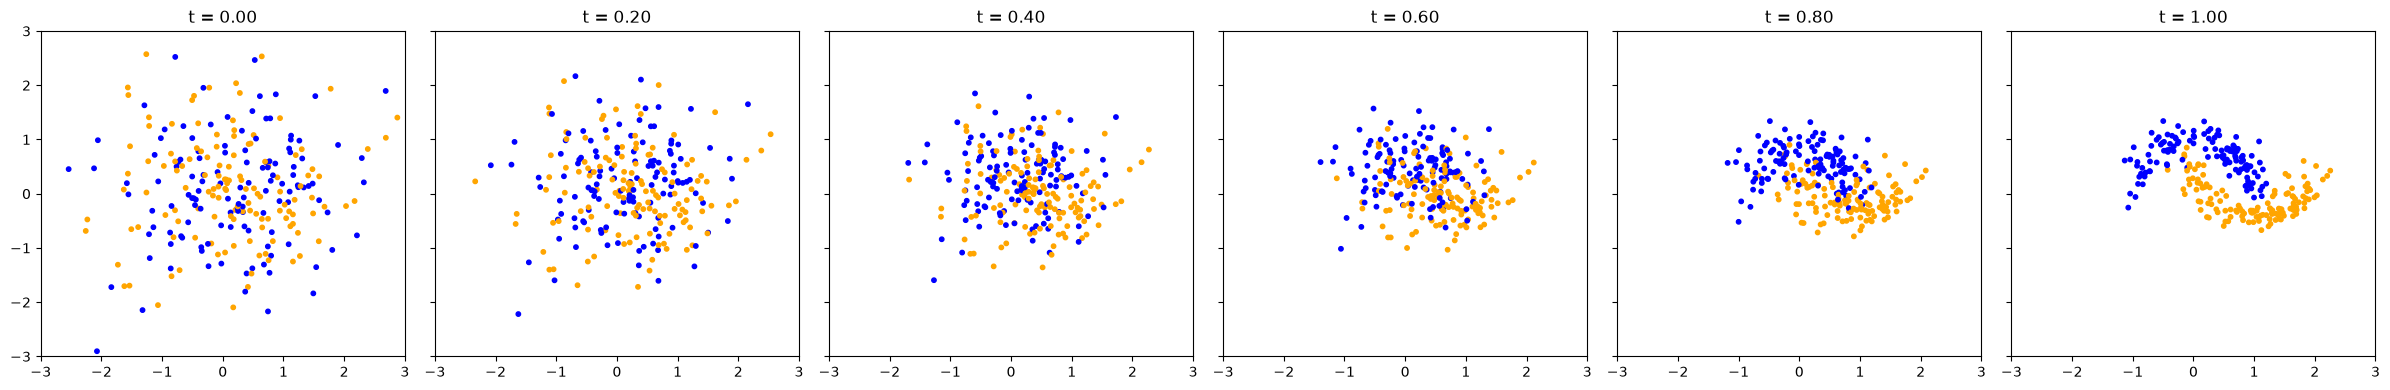

In [12]:
# --- evaluation / visualisation section --------------------------
n_samples = 256                    

sigma = 1.0
x      = torch.randn(n_samples, 2) * sigma     # (n_samples, 2)

# if you just want random labels –– otherwise load real labels here
c_eval = torch.randint(0, 2, (n_samples, 1), dtype=torch.float32)  # (n_samples, 1)

# colours for the scatter (same length as x)
colors  = ['blue' if lbl == 0 else 'orange' for lbl in c_eval.squeeze().tolist()]

# -----------------------------------------------------------------
n_steps      = 100
plot_every   = 20
plot_indices = list(range(0, n_steps + 1, plot_every))
if plot_indices[-1] != n_steps:
    plot_indices.append(n_steps)

fig, axes   = plt.subplots(1, len(plot_indices), figsize=(4 * len(plot_indices), 4),
                           sharex=True, sharey=True)
time_steps  = torch.linspace(0, 1.0, n_steps + 1)

# initial frame
axes[0].scatter(x[:, 0], x[:, 1], s=10, c=colors)
axes[0].set_title(f't = {time_steps[0]:.2f}')
axes[0].set_xlim(-3.0, 3.0)
axes[0].set_ylim(-3.0, 3.0)

plot_count = 0
with torch.no_grad():                         # no gradients while sampling
    for i in range(n_steps):
        x = cond_flow.step(x_t=x,
                      t_start=time_steps[i],
                      t_end=time_steps[i + 1],
                      c=c_eval)               # 2️⃣ use the same‑sized label tensor
        if (i + 1) in plot_indices:
            plot_count += 1
            axes[plot_count].scatter(x[:, 0], x[:, 1], s=10, c=colors)
            axes[plot_count].set_title(f't = {time_steps[i + 1]:.2f}')
            axes[plot_count].set_xlim(-3.0, 3.0)
            axes[plot_count].set_ylim(-3.0, 3.0)

plt.tight_layout()
plt.show()

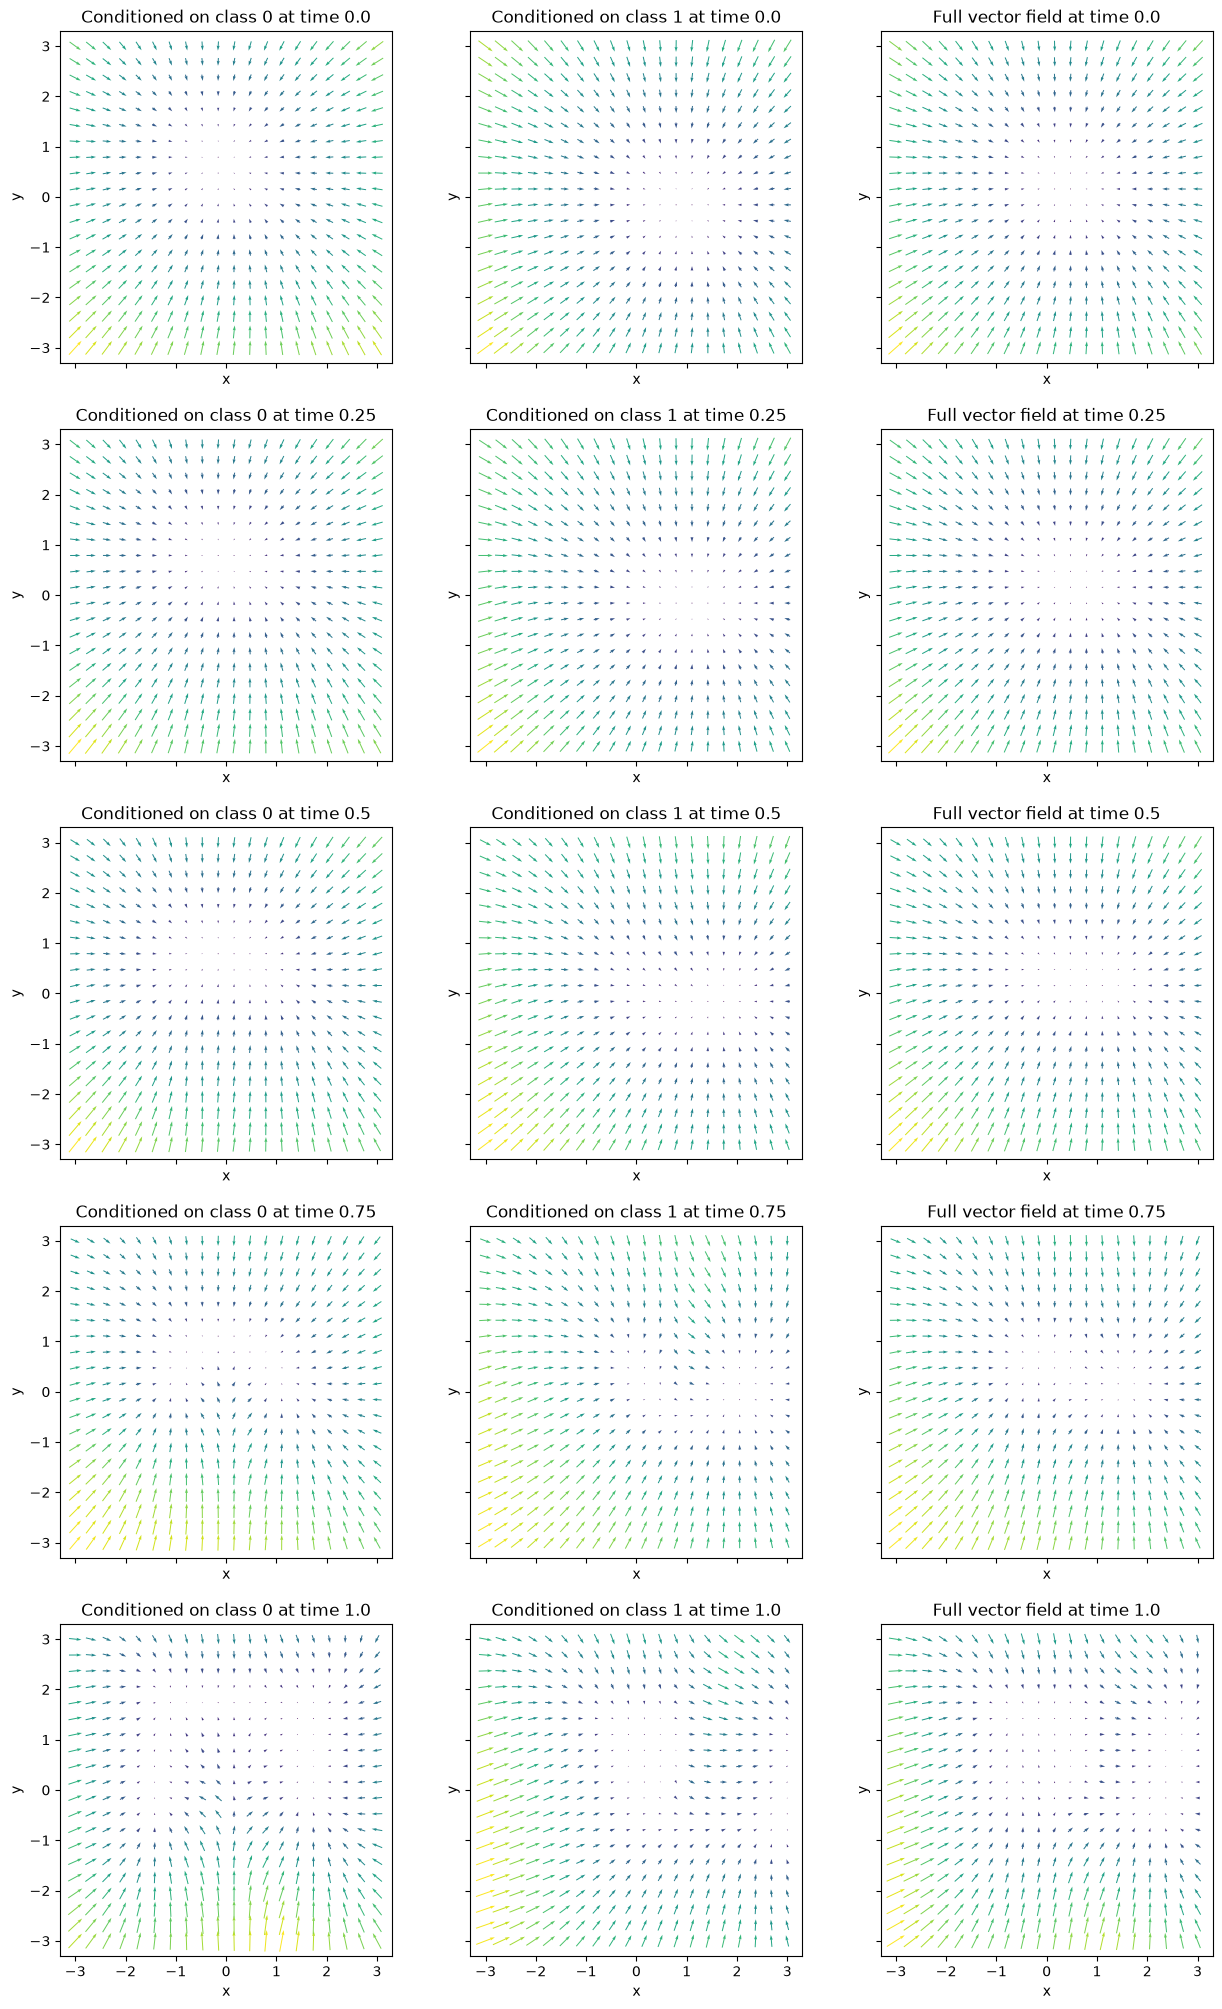

In [13]:
from functools import partial
flow_c1 = partial(cond_flow, c=Tensor([[1.0]]))
flow_c0 = partial(cond_flow, c=Tensor([[0.0]]))
def full_vf(t, x_t):
    return 0.5*flow_c1(t=t, x_t=x_t) + 0.5*flow_c0(t=t, x_t=x_t)

fig, axs = plt.subplots(5, 3, figsize=(15, 5*5), sharex=True, sharey=True)

for i in range(5):
    t = i/(5-1)
    plot_velocity_field(flow_c0, t=t, lim=3.0, n=20, ax=axs[i, 0])
    axs[i, 0].set_title(f'Conditioned on class 0 at time {t}')
    plot_velocity_field(flow_c1, t=t, lim=3.0, n=20, ax=axs[i, 1])
    axs[i, 1].set_title(f'Conditioned on class 1 at time {t}')
    plot_velocity_field(full_vf, t=t, lim=3.0, n=20, ax=axs[i, 2])
    axs[i, 2].set_title(f'Full vector field at time {t}')

plt.show()

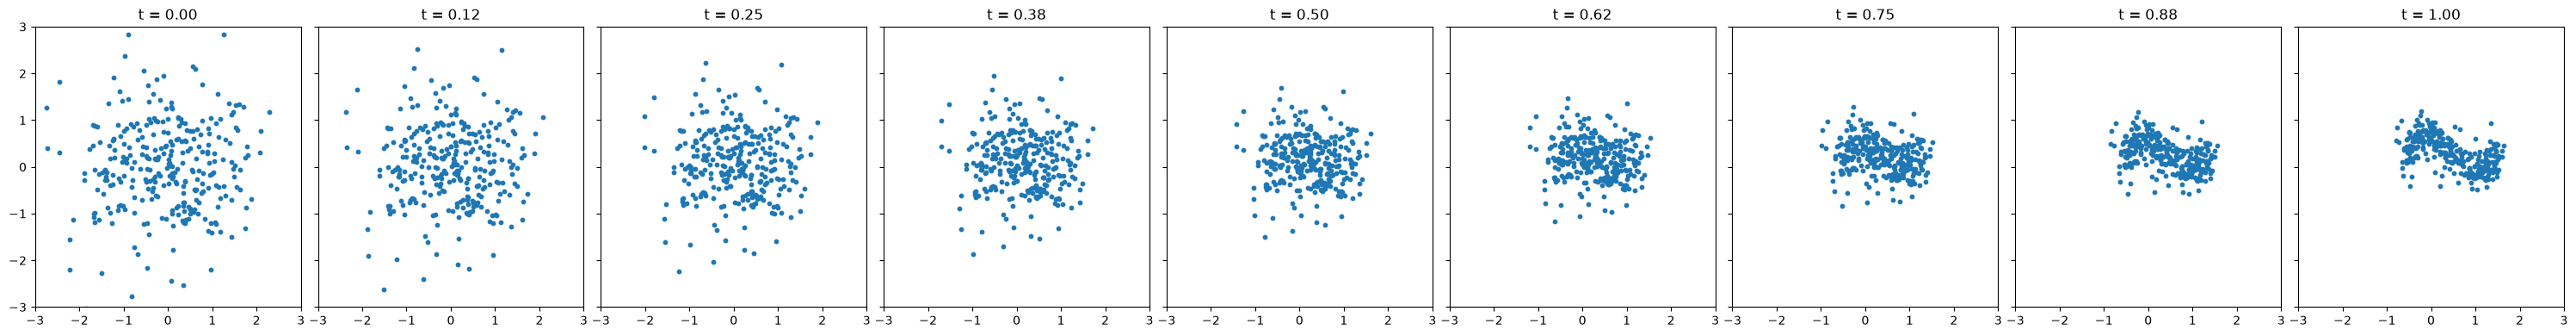

In [14]:
def full_vf(t, x_t):
    return 0.5*flow_c1(t=t, x_t=x_t) + 0.5*flow_c0(t=t, x_t=x_t)

def full_vf_step(x_t: Tensor, t_start: Tensor, t_end: Tensor) -> Tensor:
        t_start = t_start.view(1, 1).expand(x_t.shape[0], 1)
        return x_t + (t_end - t_start) * full_vf(t=t_start + (t_end - t_start) / 2, x_t= x_t + full_vf(x_t=x_t, t=t_start) * (t_end - t_start) / 2)


x = torch.randn(300, 2)
n_steps = 8
fig, axes = plt.subplots(1, n_steps + 1, figsize=(30, 4), sharex=True, sharey=True)
time_steps = torch.linspace(0, 1.0, n_steps + 1)

axes[0].scatter(x.detach()[:, 0], x.detach()[:, 1], s=10)
axes[0].set_title(f't = {time_steps[0]:.2f}')
axes[0].set_xlim(-3.0, 3.0)
axes[0].set_ylim(-3.0, 3.0)

for i in range(n_steps):
    x = full_vf_step(x_t=x, t_start=time_steps[i], t_end=time_steps[i + 1])
    axes[i + 1].scatter(x.detach()[:, 0], x.detach()[:, 1], s=10)
    axes[i + 1].set_title(f't = {time_steps[i + 1]:.2f}')

plt.tight_layout()
plt.show()

## Optimal transport coupling

In [37]:
from scipy.optimize import linear_sum_assignment
from scipy.spatial import distance

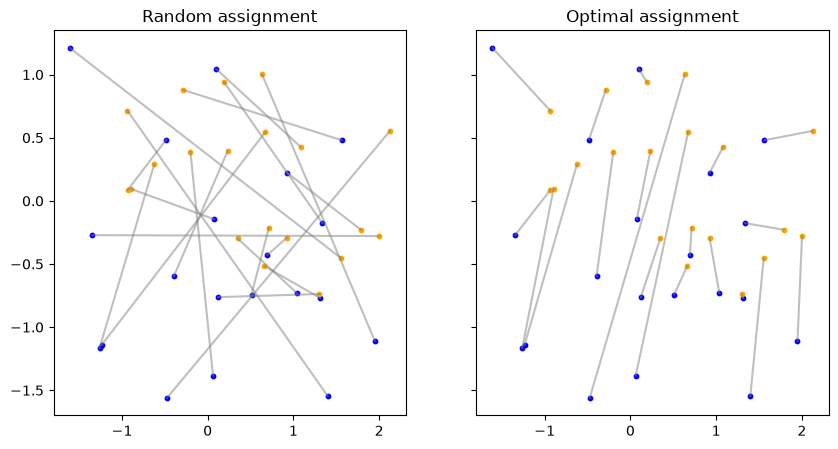

In [40]:
N = 20

x_1 = Tensor(make_moons(N, noise=0.15)[0])
x_0 = torch.randn_like(x_1)

fig, axs = plt.subplots(1, 2, figsize=(10, 5), sharex=True, sharey=True)
axs[0].scatter(x_0[:, 0], x_0[:, 1], s=10, c='blue')
axs[0].scatter(x_1[:, 0], x_1[:, 1], s=10, c='orange')
for a, b in zip(x_0.cpu().numpy(), x_1.cpu().numpy()):
    axs[0].plot(*zip(a, b), c='gray', alpha=0.5)

axs[0].set_title('Random assignment')


cost = distance.cdist(x_0.cpu().numpy(), x_1.cpu().numpy())
row_ind, col_ind = linear_sum_assignment(cost)

axs[1].scatter(x_0[row_ind, 0], x_0[row_ind, 1], s=10, c='blue')
axs[1].scatter(x_1[col_ind, 0], x_1[col_ind, 1], s=10, c='orange')
for a, b in zip(x_0[row_ind].cpu().numpy(), x_1[col_ind].cpu().numpy()):
    axs[1].plot(*zip(a, b), c='gray', alpha=0.5)

axs[1].set_title('Optimal assignment')

plt.show()